In [1]:
from sklearn.preprocessing import StandardScaler
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import numpy as np 
np.random.seed(42)

n_redundant = 7
weights = np.random.randn(3, n_redundant)  # una colonna di pesi per ogni feature ridondante
noise = np.random.normal(0, 0.5, size=(500, n_redundant))

X_core, y = make_blobs(n_samples=500, n_features=3, centers=4, random_state=42)

X_redundant = X_core @ weights + noise
X = np.hstack([X_core, X_redundant])

In [2]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

In [3]:
silhouette_scores_10d = []

for k in range(2, 11):
    cluster_to_find_k = KMeans(n_clusters=k, init='k-means++', n_init=20, random_state=42)
    cluster_to_find_k.fit(X_scaled)
    silhouette_scores_10d.append(silhouette_score(X_scaled, cluster_to_find_k.labels_))
    
print(f"Silhouette scores: {silhouette_scores_10d}")

Silhouette scores: [0.5779939805021388, 0.7936401346457276, 0.755248521067995, 0.6126898684110044, 0.46898211820016833, 0.3676486224709405, 0.27373231950532206, 0.26458107827637356, 0.25691846099116256]


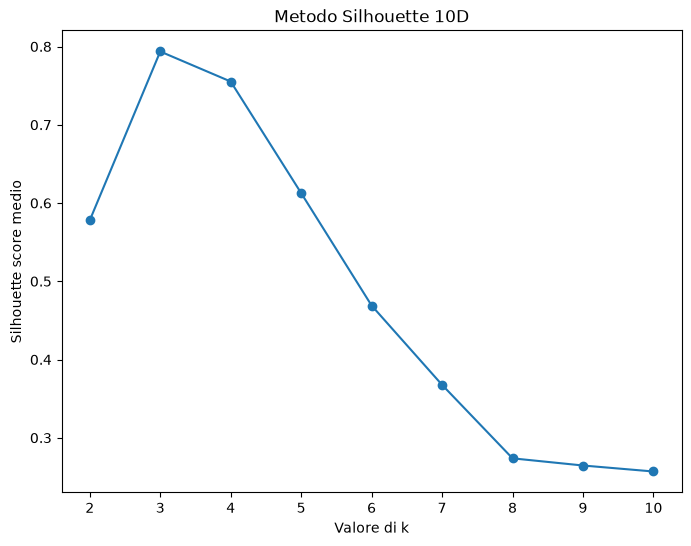

In [4]:
plt.figure(figsize=(8, 6))
plt.plot(range(2, 11), silhouette_scores_10d, marker='o')
plt.xlabel('Valore di k')
plt.ylabel('Silhouette score medio')
plt.title('Metodo Silhouette 10D')
plt.show()

In [5]:
import scipy

X_core2, y2, true_centers = make_blobs(n_samples=500, n_features=3, centers=4, random_state=42, return_centers=True)
print(scipy.spatial.distance.pdist(true_centers))

[20.13500014  7.05466415 20.32721672 19.94670024 16.64658547 22.57007338]


In [6]:
cluster = KMeans(n_clusters=3, n_init=20, random_state=42, init='k-means++')
cluster.fit(X_scaled)

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",3
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",20
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary <random_state>`.",42
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",300
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'
Name,Type,Value
"cluster_centers_ cluster_centers_: ndarray of shape (n_clusters, n_features)Coordinates of cluster centers. If the algorithm stops before fullyconverging (see ``tol`` and ``max_iter``), these will not beconsistent with ``labels_``.","ndarray[float64](3, 10)","[[ 1

In [7]:
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)
print(f'Explained Variance Ratio: {pca.explained_variance_ratio_}')

# Varianza spiegata cumulativa con 3 componenti
pca3 = PCA(n_components=3, random_state=42)
pca3.fit(X_scaled)
print(f'Varianza spiegata cumulativa: {np.cumsum(pca3.explained_variance_ratio_)}')

Explained Variance Ratio: [0.53188513 0.42279789]
Varianza spiegata cumulativa: [0.53188513 0.95468301 0.99790045]


In [8]:
silhouette_scores_2d = []

for k in range(2, 11):
    cluster_to_find_k = KMeans(n_clusters=k, init='k-means++', n_init=20, random_state=42)
    cluster_to_find_k.fit(X_pca)
    silhouette_scores_2d.append(silhouette_score(X_pca, cluster_to_find_k.labels_))
print(f"Silhouette scores 2D: {silhouette_scores_2d}")

Silhouette scores 2D: [0.6218649623858439, 0.8617430683603862, 0.7081367947819088, 0.5887996308432704, 0.4701697441517599, 0.39837235973199575, 0.38634944502432245, 0.375257879242584, 0.3673530319603239]


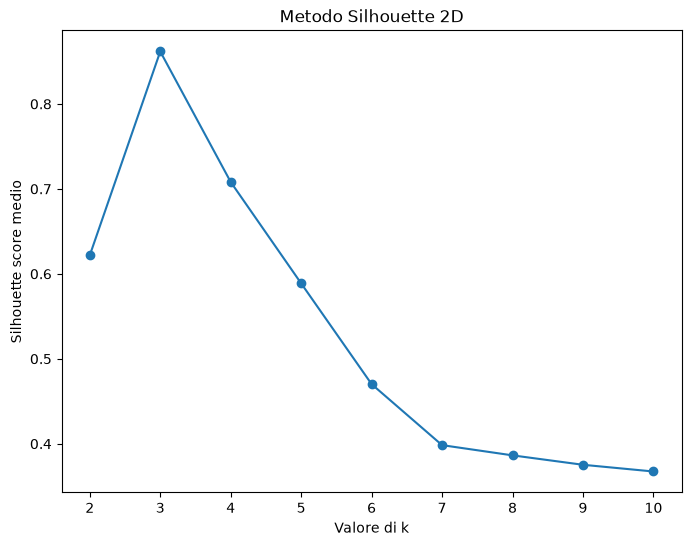

In [9]:
plt.figure(figsize=(8, 6))
plt.plot(range(2, 11), silhouette_scores_2d, marker='o')
plt.xlabel('Valore di k')
plt.ylabel('Silhouette score medio')
plt.title('Metodo Silhouette 2D')
plt.show()

In [10]:
print(f"Silhouette k=3, 10D: {silhouette_scores_10d[1]:.4f}")
print(f"Silhouette k=3, 2D:  {silhouette_scores_2d[1]:.4f}")

Silhouette k=3, 10D: 0.7936
Silhouette k=3, 2D:  0.8617


In [11]:
print(f"Silhouette k=3, 10D: {silhouette_scores_10d[1]:.4f}")
print(f"Silhouette k=3, 2D:  {silhouette_scores_2d[1]:.4f}")

Silhouette k=3, 10D: 0.7936
Silhouette k=3, 2D:  0.8617


In [12]:
cluster_2d = KMeans(n_clusters=3, n_init=20, random_state=42, init='k-means++')
cluster_2d.fit(X_pca)

from sklearn.metrics import adjusted_rand_score

# ARI tra 10D e 2D, e di ciascuna con la y di make_blobs
print(f"ARI 10D vs 2D, k=3: {adjusted_rand_score(cluster.labels_, cluster_2d.labels_)}")
print(f"ARI 10D vs y, k=3: {adjusted_rand_score(y, cluster.labels_)}")
print(f"ARI 2D vs y, k=3: {adjusted_rand_score(y, cluster_2d.labels_)}")

cluster_k4 = KMeans(n_clusters=4, n_init=20, random_state=42, init='k-means++')
cluster_k4.fit(X_scaled)
cluster_2d_k4 = KMeans(n_clusters=4, n_init=20, random_state=42, init='k-means++')
cluster_2d_k4.fit(X_pca)

print(f"ARI 10D vs 2D, k=4: {adjusted_rand_score(cluster_k4.labels_, cluster_2d_k4.labels_)}")
print(f"ARI 10D vs y, k=4: {adjusted_rand_score(y, cluster_k4.labels_)}")
print(f"ARI 2D vs y, k=4: {adjusted_rand_score(y, cluster_2d_k4.labels_)}")

ARI 10D vs 2D, k=3: 1.0
ARI 10D vs y, k=3: 0.7130534790109259
ARI 2D vs y, k=3: 0.7130534790109259


ARI 10D vs 2D, k=4: 0.9196483730336978
ARI 10D vs y, k=4: 1.0
ARI 2D vs y, k=4: 0.9196483730336978


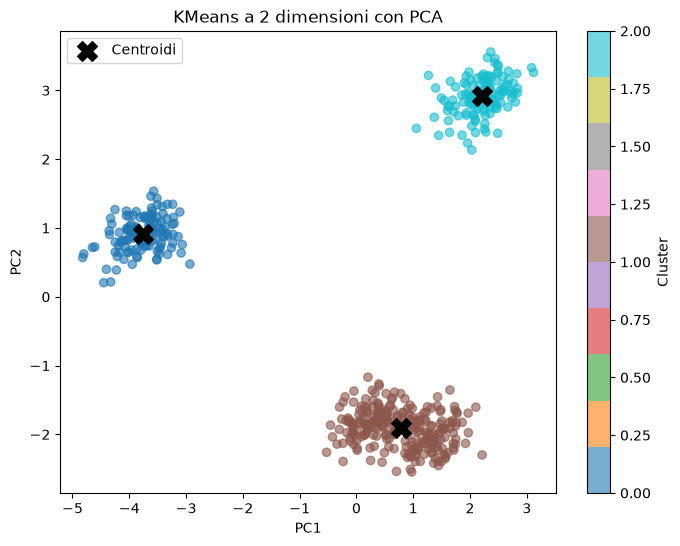

In [13]:
plt.figure(figsize=(8, 6))
scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=cluster_2d.labels_, cmap='tab10', alpha=0.6)
plt.scatter(cluster_2d.cluster_centers_[:, 0], cluster_2d.cluster_centers_[:, 1], c='black', marker='X', s=200, label='Centroidi')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('KMeans a 2 dimensioni con PCA')
plt.colorbar(scatter, label='Cluster')
plt.legend()
plt.show()